# Notebook 02B — Tracking Evaluation & Stabilization

## AI Exam Cheating Tracking Project

This notebook evaluates tracking quality **before** adding cheating detection.

### Why this step is necessary
A high number of unique Track IDs does not necessarily mean many students.  
The same student may receive multiple IDs if tracking is lost and recreated.

This problem is called:

- **ID fragmentation**
- **ID switch**
- **Track re-initialization**

### Goal
- Compare **ByteTrack** and **BoT-SORT**.
- Measure Track ID behavior across time.
- Save diagnostic CSV files.
- Tune ByteTrack parameters.
- Select the most stable tracker for the next notebook.

> No cheating detection is added here.


## 1. Install packages

In [1]:
!pip install -q ultralytics opencv-python pandas matplotlib

## 2. Imports and GPU check

In [2]:
from pathlib import Path
import shutil
import yaml
import cv2
import pandas as pd
import matplotlib.pyplot as plt
import torch

from ultralytics import YOLO
from google.colab import drive
from IPython.display import Video, display

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


## 3. Mount Google Drive

In [3]:
drive.mount('/content/drive')

Mounted at /content/drive


## 4. Paths

In [4]:
BASE_DIR = Path("/content/drive/MyDrive/cheating tracking")
VIDEO_DIR = BASE_DIR / "videos"

OUTPUT_DIR = BASE_DIR / "outputs"
EVAL_DIR = OUTPUT_DIR / "tracking_evaluation"
TRACKER_DIR = BASE_DIR / "tracker_configs"

EVAL_DIR.mkdir(parents=True, exist_ok=True)
TRACKER_DIR.mkdir(parents=True, exist_ok=True)

print("VIDEO_DIR:", VIDEO_DIR)
print("EVAL_DIR:", EVAL_DIR)
print("TRACKER_DIR:", TRACKER_DIR)


VIDEO_DIR: /content/drive/MyDrive/cheating tracking/videos
EVAL_DIR: /content/drive/MyDrive/cheating tracking/outputs/tracking_evaluation
TRACKER_DIR: /content/drive/MyDrive/cheating tracking/tracker_configs


## 5. Load videos

In [5]:
video_files = sorted(
    list(VIDEO_DIR.glob("*.mp4")) +
    list(VIDEO_DIR.glob("*.avi")) +
    list(VIDEO_DIR.glob("*.mov")) +
    list(VIDEO_DIR.glob("*.mkv"))
)

for i, v in enumerate(video_files):
    print(i, v.name)

assert len(video_files) > 0, "No videos found."


0 video1.mp4
1 video2.mp4
2 video3.mp4
3 video4.mp4


## 6. Load YOLO11

In [6]:
DEVICE = 0 if torch.cuda.is_available() else "cpu"
MODEL_PATH = "yolo11n.pt"

print("Device:", DEVICE)


Device: 0


## 7. Tracking evaluation function

For each frame we store:
- frame number
- video time
- Track ID
- bounding box
- detection confidence

This lets us inspect how IDs appear/disappear across the video.


In [7]:
def evaluate_tracker_on_video(
    input_video,
    tracker_config,
    tracker_name,
    conf=0.35,
    save_video=True
):
    model = YOLO(MODEL_PATH)

    cap = cv2.VideoCapture(str(input_video))

    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    output_video = EVAL_DIR / f"{input_video.stem}_{tracker_name}.mp4"
    output_csv = EVAL_DIR / f"{input_video.stem}_{tracker_name}.csv"

    writer = None
    if save_video:
        fourcc = cv2.VideoWriter_fourcc(*"mp4v")
        writer = cv2.VideoWriter(
            str(output_video),
            fourcc,
            fps,
            (width, height)
        )

    records = []
    unique_ids = set()
    frame_idx = 0

    while True:
        ok, frame = cap.read()
        if not ok:
            break

        result = model.track(
            source=frame,
            persist=True,
            tracker=str(tracker_config),
            classes=[0],
            conf=conf,
            device=DEVICE,
            verbose=False
        )[0]

        annotated = frame.copy()

        if result.boxes is not None and result.boxes.id is not None:
            boxes = result.boxes.xyxy.cpu().numpy()
            ids = result.boxes.id.int().cpu().tolist()
            confs = result.boxes.conf.cpu().tolist()

            for box, tid, det_conf in zip(boxes, ids, confs):
                x1, y1, x2, y2 = map(int, box)
                unique_ids.add(tid)

                records.append({
                    "video": input_video.name,
                    "tracker": tracker_name,
                    "frame": frame_idx,
                    "time_sec": frame_idx / fps if fps > 0 else 0,
                    "track_id": tid,
                    "confidence": float(det_conf),
                    "x1": x1,
                    "y1": y1,
                    "x2": x2,
                    "y2": y2,
                    "cx": (x1 + x2) / 2,
                    "cy": (y1 + y2) / 2,
                    "w": x2 - x1,
                    "h": y2 - y1,
                })

                cv2.rectangle(
                    annotated,
                    (x1, y1),
                    (x2, y2),
                    (0, 255, 0),
                    3
                )

                cv2.putText(
                    annotated,
                    f"ID {tid}",
                    (x1, max(20, y1 - 8)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.75,
                    (0, 255, 0),
                    2
                )

        if writer is not None:
            writer.write(annotated)

        frame_idx += 1

        if frame_idx % 100 == 0:
            print(
                f"{input_video.name} | {tracker_name}: "
                f"{frame_idx}/{total_frames}"
            )

    cap.release()
    if writer is not None:
        writer.release()

    df = pd.DataFrame(records)
    df.to_csv(output_csv, index=False)

    return {
        "video": input_video.name,
        "tracker": tracker_name,
        "frames": frame_idx,
        "unique_ids": len(unique_ids),
        "ids": sorted(unique_ids),
        "csv": str(output_csv),
        "video_output": str(output_video) if save_video else None
    }, df


## 8. Compare ByteTrack and BoT-SORT on one video first

In [8]:
TEST_VIDEO = video_files[1] if len(video_files) > 1 else video_files[0]

print("Test video:", TEST_VIDEO.name)


Test video: video2.mp4


In [9]:
bytetrack_summary, bytetrack_df = evaluate_tracker_on_video(
    TEST_VIDEO,
    "bytetrack.yaml",
    "bytetrack_default"
)

botsort_summary, botsort_df = evaluate_tracker_on_video(
    TEST_VIDEO,
    "botsort.yaml",
    "botsort_default"
)

comparison = pd.DataFrame([
    bytetrack_summary,
    botsort_summary
])

comparison


requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 145ms
Prepared 1 package in 25ms
Installed 1 package in 1ms
 + lap==0.5.13

requirements: AutoUpdate success ✅ 0.4s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

video2.mp4 | bytetrack_default: 100/261
video2.mp4 | bytetrack_default: 200/261
video2.mp4 | botsort_default: 100/261
video2.mp4 | botsort_default: 200/261


,video,tracker,frames,unique_ids,ids,csv,video_output
0,video2.mp4,bytetrack_default,261,19,"[1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 14, 15, 1...",/content/drive/MyDrive/cheating tracking/outpu...,/content/drive/MyDrive/cheating tracking/outpu...
1,video2.mp4,botsort_default,261,19,"[1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 14, 15, 1...",/content/drive/MyDrive/cheating tracking/outpu...,/content/drive/MyDrive/cheating tracking/outpu...


## 9. Preview both outputs

In [10]:
print("ByteTrack")
display(Video(bytetrack_summary["video_output"], embed=True, width=850))

print("BoT-SORT")
display(Video(botsort_summary["video_output"], embed=True, width=850))


Output hidden; open in https://colab.research.google.com to view.

## 10. Track lifespan analysis

A real student usually produces a track that lasts many consecutive frames.

Very short tracks often indicate:
- false detections,
- ID fragmentation,
- temporary tracking loss.


In [11]:
def track_lifespan_table(df):
    if len(df) == 0:
        return pd.DataFrame()

    g = df.groupby("track_id")

    life = g.agg(
        first_frame=("frame", "min"),
        last_frame=("frame", "max"),
        detections=("frame", "count"),
        mean_conf=("confidence", "mean")
    ).reset_index()

    life["span_frames"] = (
        life["last_frame"] - life["first_frame"] + 1
    )

    life["coverage_ratio"] = (
        life["detections"] / life["span_frames"]
    )

    return life.sort_values(
        "detections",
        ascending=False
    )

byte_life = track_lifespan_table(bytetrack_df)
bot_life = track_lifespan_table(botsort_df)

print("ByteTrack lifespan")
display(byte_life)

print("BoT-SORT lifespan")
display(bot_life)


ByteTrack lifespan


,track_id,first_frame,last_frame,detections,mean_conf,span_frames,coverage_ratio
0,1,0,260,261,0.880098,261,1.000000
1,2,0,260,221,0.731092,261,0.846743
12,15,84,260,177,0.701811,177,1.000000
10,12,69,260,150,0.608921,192,0.781250
4,5,0,164,142,0.521479,165,0.860606
9,11,40,190,134,0.666042,151,0.887417
3,4,0,136,125,0.656930,137,0.912409
11,14,83,202,60,0.620965,120,0.500000
6,7,0,56,54,0.571707,57,0.947368
2,3,0,49,50,0.789018,50,1.000000


BoT-SORT lifespan


,track_id,first_frame,last_frame,detections,mean_conf,span_frames,coverage_ratio
0,1,0,260,261,0.880098,261,1.000000
1,2,0,260,221,0.731092,261,0.846743
12,15,84,260,177,0.701811,177,1.000000
10,12,69,260,150,0.608921,192,0.781250
4,5,0,164,142,0.521479,165,0.860606
9,11,40,190,134,0.666042,151,0.887417
3,4,0,136,125,0.656930,137,0.912409
11,14,83,202,60,0.620965,120,0.500000
6,7,0,56,54,0.571707,57,0.947368
2,3,0,49,50,0.789018,50,1.000000


## 11. Plot Track IDs over time

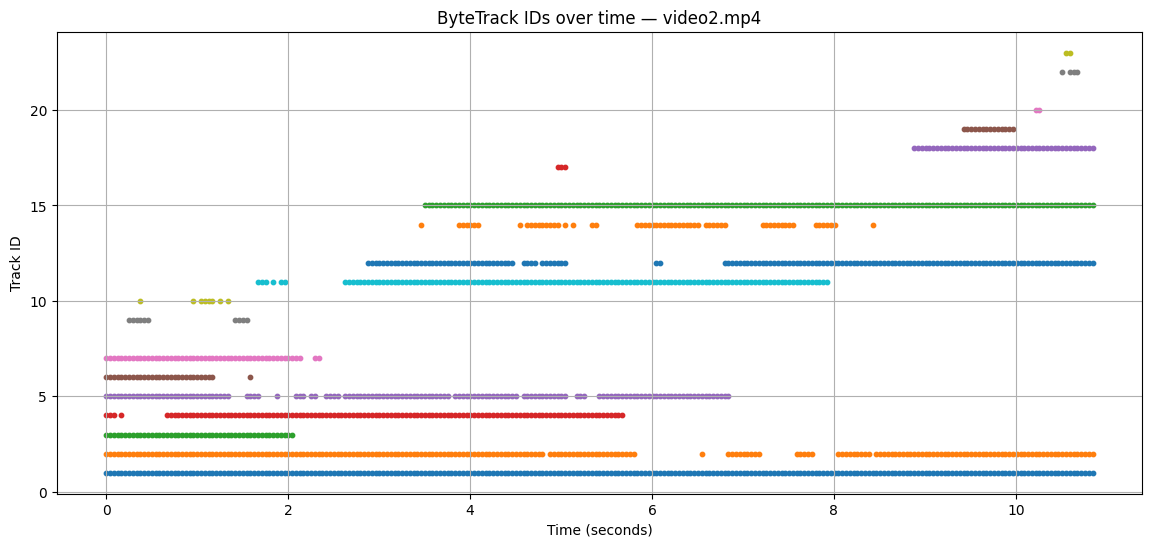

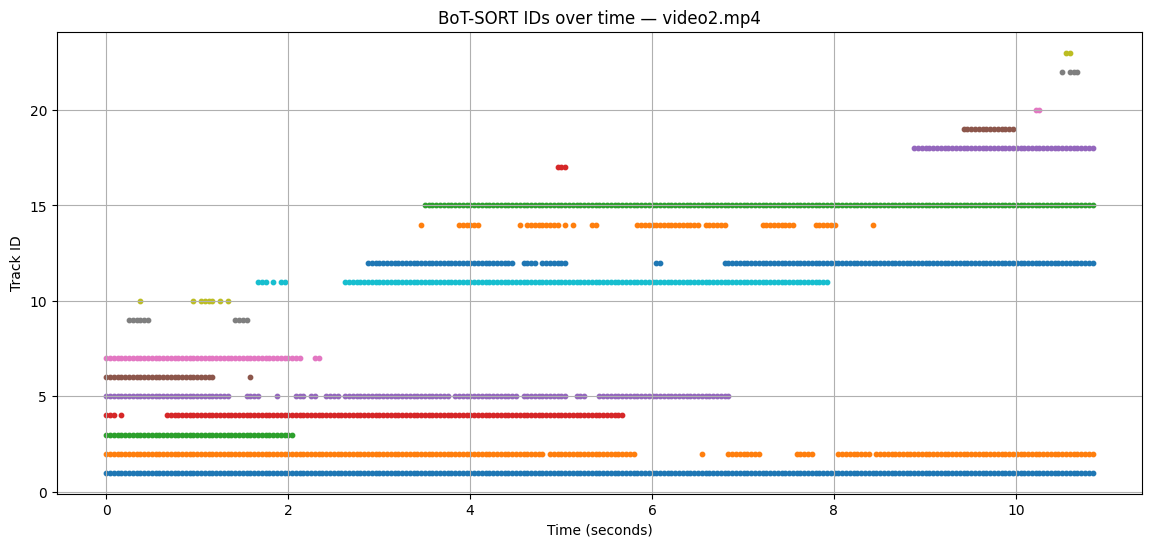

In [12]:
def plot_track_ids_over_time(df, title):
    if len(df) == 0:
        print("No data.")
        return

    plt.figure(figsize=(14, 6))

    for tid, group in df.groupby("track_id"):
        plt.scatter(
            group["time_sec"],
            [tid] * len(group),
            s=10,
            label=f"ID {tid}"
        )

    plt.xlabel("Time (seconds)")
    plt.ylabel("Track ID")
    plt.title(title)
    plt.grid(True)
    plt.show()

plot_track_ids_over_time(
    bytetrack_df,
    f"ByteTrack IDs over time — {TEST_VIDEO.name}"
)

plot_track_ids_over_time(
    botsort_df,
    f"BoT-SORT IDs over time — {TEST_VIDEO.name}"
)


## 12. Create a tuned ByteTrack configuration

We create a custom tracker YAML.

The main parameters we will adjust are:

- `track_high_thresh`
- `track_low_thresh`
- `new_track_thresh`
- `track_buffer`
- `match_thresh`

A larger `track_buffer` can help keep a lost student alive for more frames.
A stricter `new_track_thresh` can reduce unnecessary new IDs.


In [13]:
custom_bytetrack_yaml = TRACKER_DIR / "bytetrack_exam.yaml"

custom_config = {
    "tracker_type": "bytetrack",

    # Detection association thresholds
    "track_high_thresh": 0.35,
    "track_low_thresh": 0.10,

    # Higher threshold before creating a new track
    "new_track_thresh": 0.45,

    # Keep missing tracks alive longer
    "track_buffer": 60,

    # Association matching
    "match_thresh": 0.80,

    # Fuse detection confidence with IoU matching
    "fuse_score": True
}

with open(custom_bytetrack_yaml, "w") as f:
    yaml.safe_dump(
        custom_config,
        f,
        sort_keys=False
    )

print(custom_bytetrack_yaml)
print(custom_config)


/content/drive/MyDrive/cheating tracking/tracker_configs/bytetrack_exam.yaml
{'tracker_type': 'bytetrack', 'track_high_thresh': 0.35, 'track_low_thresh': 0.1, 'new_track_thresh': 0.45, 'track_buffer': 60, 'match_thresh': 0.8, 'fuse_score': True}


## 13. Evaluate tuned ByteTrack

In [14]:
tuned_summary, tuned_df = evaluate_tracker_on_video(
    TEST_VIDEO,
    custom_bytetrack_yaml,
    "bytetrack_tuned"
)

comparison_tuned = pd.DataFrame([
    bytetrack_summary,
    botsort_summary,
    tuned_summary
])

comparison_tuned


video2.mp4 | bytetrack_tuned: 100/261
video2.mp4 | bytetrack_tuned: 200/261


,video,tracker,frames,unique_ids,ids,csv,video_output
0,video2.mp4,bytetrack_default,261,19,"[1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 14, 15, 1...",/content/drive/MyDrive/cheating tracking/outpu...,/content/drive/MyDrive/cheating tracking/outpu...
1,video2.mp4,botsort_default,261,19,"[1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 14, 15, 1...",/content/drive/MyDrive/cheating tracking/outpu...,/content/drive/MyDrive/cheating tracking/outpu...
2,video2.mp4,bytetrack_tuned,261,14,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]",/content/drive/MyDrive/cheating tracking/outpu...,/content/drive/MyDrive/cheating tracking/outpu...


## 14. Inspect tuned Track lifespans

,track_id,first_frame,last_frame,detections,mean_conf,span_frames,coverage_ratio
0,1,0,260,261,0.880098,261,1.000000
2,3,0,260,228,0.719832,261,0.873563
1,2,0,260,221,0.731092,261,0.846743
9,10,73,260,146,0.614025,188,0.776596
4,5,0,164,142,0.521479,165,0.860606
8,9,41,190,133,0.667666,150,0.886667
3,4,0,136,125,0.656930,137,0.912409
7,8,10,202,68,0.598120,193,0.352332
5,6,2,56,52,0.577423,55,0.945455
10,11,213,260,48,0.693233,48,1.000000


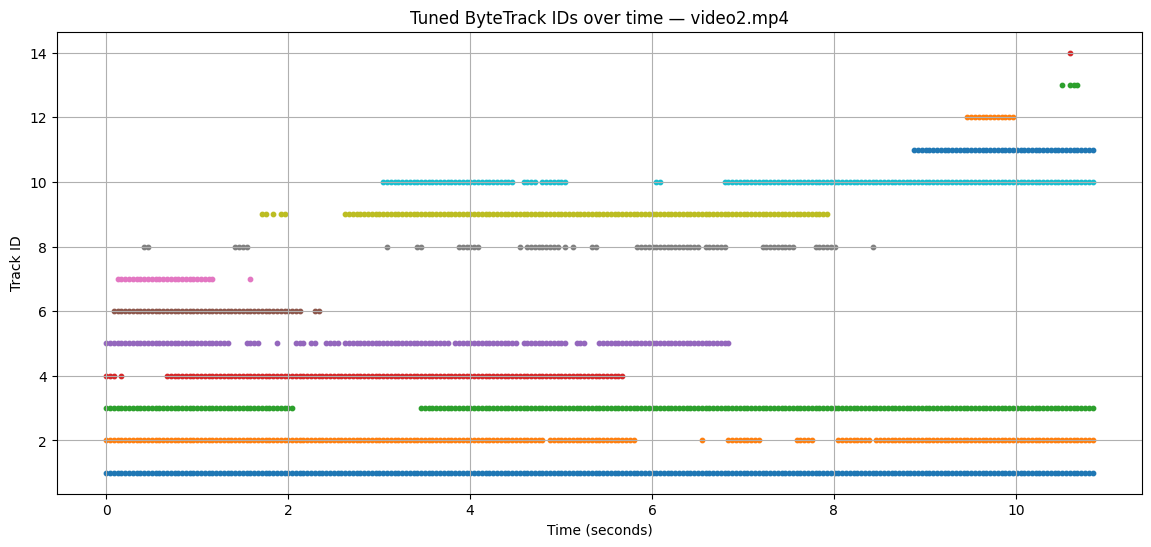

In [15]:
tuned_life = track_lifespan_table(tuned_df)
display(tuned_life)

plot_track_ids_over_time(
    tuned_df,
    f"Tuned ByteTrack IDs over time — {TEST_VIDEO.name}"
)


## 15. Simple fragmentation indicators

These indicators are not full MOT benchmark metrics, because we do not have ground-truth identities.

But they are useful diagnostics:

- **Unique IDs**: lower is usually better if the real number of students is fixed.
- **Short-track count**: fewer is better.
- **Median detections per track**: larger is usually better.
- **Mean coverage ratio**: larger means tracks are more continuous.


In [16]:
def tracker_diagnostics(df, tracker_name, short_track_threshold=20):
    life = track_lifespan_table(df)

    if len(life) == 0:
        return {
            "tracker": tracker_name,
            "unique_ids": 0,
            "short_tracks": 0,
            "median_detections_per_track": 0,
            "mean_coverage_ratio": 0
        }

    return {
        "tracker": tracker_name,
        "unique_ids": len(life),
        "short_tracks": int(
            (life["detections"] < short_track_threshold).sum()
        ),
        "median_detections_per_track": round(
            life["detections"].median(),
            2
        ),
        "mean_coverage_ratio": round(
            life["coverage_ratio"].mean(),
            3
        )
    }

diag_df = pd.DataFrame([
    tracker_diagnostics(
        bytetrack_df,
        "ByteTrack Default"
    ),
    tracker_diagnostics(
        botsort_df,
        "BoT-SORT Default"
    ),
    tracker_diagnostics(
        tuned_df,
        "ByteTrack Tuned"
    )
])

diag_df


,tracker,unique_ids,short_tracks,median_detections_per_track,mean_coverage_ratio
0,ByteTrack Default,19,7,50.0,0.840
1,BoT-SORT Default,19,7,50.0,0.840
2,ByteTrack Tuned,14,3,96.5,0.857


## 16. Run the selected tracker on all videos

Start by selecting the tracker that visually preserves identities best.

Recommended first choice after testing:

```python
SELECTED_TRACKER = custom_bytetrack_yaml
```

If BoT-SORT is visibly better, use:

```python
SELECTED_TRACKER = "botsort.yaml"
```


In [17]:
SELECTED_TRACKER = custom_bytetrack_yaml
SELECTED_TRACKER_NAME = "bytetrack_tuned"

print("Selected tracker:", SELECTED_TRACKER)


Selected tracker: /content/drive/MyDrive/cheating tracking/tracker_configs/bytetrack_exam.yaml


In [18]:
all_summaries = []
all_diagnostics = []

for video_path in video_files:

    summary, df = evaluate_tracker_on_video(
        video_path,
        SELECTED_TRACKER,
        SELECTED_TRACKER_NAME
    )

    all_summaries.append(summary)

    diag = tracker_diagnostics(
        df,
        f"{video_path.name} - {SELECTED_TRACKER_NAME}"
    )

    diag["video"] = video_path.name
    all_diagnostics.append(diag)

all_summary_df = pd.DataFrame(all_summaries)
all_diag_df = pd.DataFrame(all_diagnostics)

print("Tracking summaries")
display(all_summary_df)

print("Diagnostics")
display(all_diag_df)


video1.mp4 | bytetrack_tuned: 100/488
video1.mp4 | bytetrack_tuned: 200/488
video1.mp4 | bytetrack_tuned: 300/488
video1.mp4 | bytetrack_tuned: 400/488
video2.mp4 | bytetrack_tuned: 100/261
video2.mp4 | bytetrack_tuned: 200/261
video3.mp4 | bytetrack_tuned: 100/256
video3.mp4 | bytetrack_tuned: 200/256
video4.mp4 | bytetrack_tuned: 100/226
video4.mp4 | bytetrack_tuned: 200/226
Tracking summaries


,video,tracker,frames,unique_ids,ids,csv,video_output
0,video1.mp4,bytetrack_tuned,488,7,"[1, 2, 3, 4, 5, 6, 7]",/content/drive/MyDrive/cheating tracking/outpu...,/content/drive/MyDrive/cheating tracking/outpu...
1,video2.mp4,bytetrack_tuned,261,14,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]",/content/drive/MyDrive/cheating tracking/outpu...,/content/drive/MyDrive/cheating tracking/outpu...
2,video3.mp4,bytetrack_tuned,256,8,"[1, 2, 3, 4, 5, 6, 7, 8]",/content/drive/MyDrive/cheating tracking/outpu...,/content/drive/MyDrive/cheating tracking/outpu...
3,video4.mp4,bytetrack_tuned,226,4,"[1, 2, 3, 4]",/content/drive/MyDrive/cheating tracking/outpu...,/content/drive/MyDrive/cheating tracking/outpu...


Diagnostics


,tracker,unique_ids,short_tracks,median_detections_per_track,mean_coverage_ratio,video
0,video1.mp4 - bytetrack_tuned,7,0,94.0,0.830,video1.mp4
1,video2.mp4 - bytetrack_tuned,14,3,96.5,0.857,video2.mp4
2,video3.mp4 - bytetrack_tuned,8,1,130.5,0.959,video3.mp4
3,video4.mp4 - bytetrack_tuned,4,1,183.5,0.956,video4.mp4
